# Local Feature Importance Demo

This notebook demonstrates the proximity-based local feature importance added to `forestgap.core`. The example uses a synthetic classification dataset with continuous features (`make_classification`) and a permutation-based perturbation step to compute local feature contributions.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

from forestgap import with_sparse_proximity

In [3]:
X, y = make_classification(
    n_samples=160,
    n_features=10,
    n_informative=3,
    n_redundant=2,
    n_repeated=0,
    n_classes=2,
    class_sep=0.5,
    flip_y=0.05,
    random_state=321,
)

columns = [f"feature_{i}" for i in range(X.shape[1])]
X_train = pd.DataFrame(X[:120], columns=columns)
X_test = pd.DataFrame(X[120:], columns=columns)
y_train = y[:120]
y_test = y[120:]

In [4]:
ProxRandomForestClassifier = with_sparse_proximity(RandomForestClassifier)

model = ProxRandomForestClassifier(
    n_estimators=80,
    random_state=21,
    prox_method="original",
    matrix_type="sparse",
    bootstrap=False,
    max_features=None,
)
model.fit(X_train, y_train)

importance, closeness, directionality = model.local_feature_importance(
    X_test.iloc[:5],
    labels=y_test[:5],
    perturbation="permute",
    return_closeness=True,
    return_directionality=True,
)

summary = importance.copy()
summary.insert(0, "true_label", y_test[:5])
summary.insert(1, "predicted_label", model.predict(X_test.iloc[:5]))
summary

,true_label,predicted_label,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9
0,1,0,1.572080,-20.706846,0.181406,-2.328306e-09,-4.656613e-09,0.589156,-2.328306e-09,-1.125348e-09,-4.850638e-11,15.525607
1,0,1,0.000000,5.225243,0.000000,0.000000e+00,0.000000e+00,0.000000,1.492885e+01,0.000000e+00,0.000000e+00,-2.399998
2,1,1,0.000000,-5.599992,0.000000,0.000000e+00,0.000000e+00,0.000000,-1.249253e+01,0.000000e+00,0.000000e+00,-10.133320
3,1,1,1.574061,-21.019971,-0.759895,4.967054e-09,3.125003e-03,2.558029,-4.999987e-03,1.771453e-09,1.738469e-08,-0.171302
4,1,1,0.000000,-5.599992,0.000000,0.000000e+00,0.000000e+00,0.000000,-1.047346e+01,0.000000e+00,0.000000e+00,-11.999984


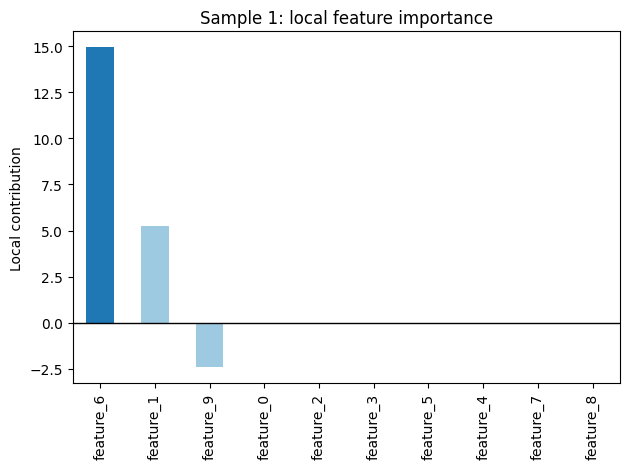

,importance,upward_effect,downward_effect,upward_count,downward_count
feature_6,14.928854,0.000000,18.661067,6,24
feature_1,5.225243,19.594662,0.000000,8,22
feature_9,-2.399998,-5.999995,0.000000,12,18
feature_0,0.000000,0.000000,0.000000,24,6
feature_2,0.000000,0.000000,0.000000,8,22
feature_3,0.000000,NaN,0.000000,0,30


In [5]:
sample_id = importance.index[1]
sample_scores = importance.loc[sample_id].sort_values(key=np.abs, ascending=False)

ax = sample_scores.plot(kind="bar", color=["#1f77b4", "#9ecae1", "#9ecae1"])
ax.axhline(0.0, color="black", linewidth=1)
ax.set_ylabel("Local contribution")
ax.set_title(f"Sample {sample_id}: local feature importance")
plt.tight_layout()
plt.show()

sample_directionality = pd.DataFrame(
    {
        "importance": importance.loc[sample_id],
        "upward_effect": directionality["upward"].loc[sample_id],
        "downward_effect": directionality["downward"].loc[sample_id],
        "upward_count": directionality["upward_count"].loc[sample_id],
        "downward_count": directionality["downward_count"].loc[sample_id],
    }
).sort_values("importance", key=np.abs, ascending=False)

sample_directionality.head(6)

### How to read the sign of the local importance scores

- Positive means the observed feature value supported the focal class used for `local_feature_importance`.
- Negative means the observed feature value pushed the sample away from that focal class.
- A value near zero means perturbing that feature had little class-relative effect locally.
- This is not a monotone statement like "larger feature value increases the prediction". The sign is about the effect of the observed value under the chosen perturbation scheme, relative to the chosen focal class.
- When `return_directionality=True`, `upward` averages the same local score over perturbations that replaced the feature with a higher numeric value, while `downward` averages it over lower-value perturbations.


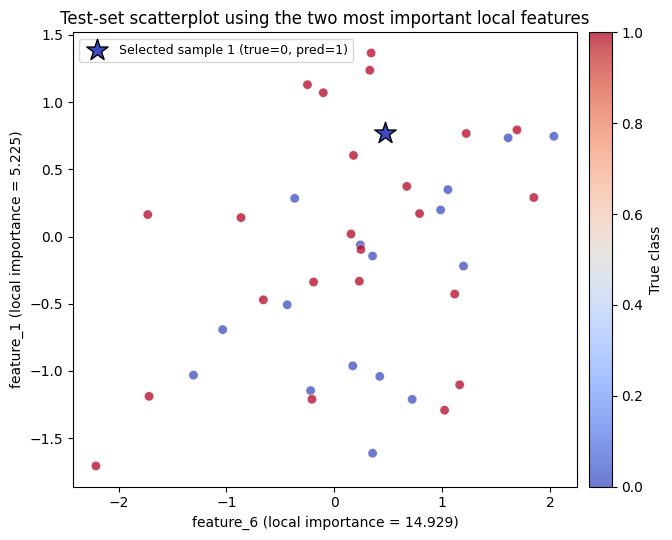

In [6]:
# -- Scatterplot of the two most important features for the selected sample --
top2_features = sample_scores.abs().nlargest(2).index.tolist()
feat_x, feat_y = top2_features

fig, ax = plt.subplots(figsize=(7, 5.5))

scatter = ax.scatter(
    X_test[feat_x],
    X_test[feat_y],
    c=y_test,
    cmap="coolwarm",
    s=45,
    alpha=0.75,
    edgecolors="white",
    linewidths=0.4,
)

ax.scatter(
    float(X_test.loc[sample_id, feat_x]),
    float(X_test.loc[sample_id, feat_y]),
    s=260,
    marker="*",
    c=[y_test[sample_id]],
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    edgecolors="black",
    linewidths=1.0,
    zorder=5,
    label=(
        f"Selected sample {sample_id} "
        f"(true={y_test[sample_id]}, pred={model.predict(X_test.loc[[sample_id]])[0]})"
    ),
)

ax.set_xlabel(f"{feat_x} (local importance = {sample_scores[feat_x]:.3f})")
ax.set_ylabel(f"{feat_y} (local importance = {sample_scores[feat_y]:.3f})")
ax.set_title("Test-set scatterplot using the two most important local features")
ax.legend(fontsize=9, loc="best")

cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label("True class")

plt.tight_layout()
plt.show()

In [7]:
importance

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9
0,1.572080,-20.706846,0.181406,-2.328306e-09,-4.656613e-09,0.589156,-2.328306e-09,-1.125348e-09,-4.850638e-11,15.525607
1,0.000000,5.225243,0.000000,0.000000e+00,0.000000e+00,0.000000,1.492885e+01,0.000000e+00,0.000000e+00,-2.399998
2,0.000000,-5.599992,0.000000,0.000000e+00,0.000000e+00,0.000000,-1.249253e+01,0.000000e+00,0.000000e+00,-10.133320
3,1.574061,-21.019971,-0.759895,4.967054e-09,3.125003e-03,2.558029,-4.999987e-03,1.771453e-09,1.738469e-08,-0.171302
4,0.000000,-5.599992,0.000000,0.000000e+00,0.000000e+00,0.000000,-1.047346e+01,0.000000e+00,0.000000e+00,-11.999984


In [8]:
closeness

{'in_group':    feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
 0   0.000138   0.411333   0.003784   0.000655   0.000367   0.000954   
 1   0.000000   0.000419   0.000000   0.000000   0.000000   0.000000   
 2   0.440677   0.359322   0.440677   0.440677   0.440677   0.440677   
 3   0.003479   0.353807   0.016128   0.005337   0.006369   0.001925   
 4   0.440677   0.359322   0.440677   0.440677   0.440677   0.440677   
 
    feature_6  feature_7  feature_8  feature_9  
 0   0.000655   0.000601   0.000524   0.000253  
 1   0.003587   0.000000   0.000000   0.153005  
 2   0.222037   0.440677   0.440677   0.290395  
 3   0.004583   0.006208   0.004562   0.005654  
 4   0.269035   0.440677   0.440677   0.263276  ,
 'out_group':    feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
 0   0.143131   0.004202   0.057105   0.062503   0.063905   0.052956   
 1   0.440677   0.353403   0.440677   0.440677   0.440677   0.440677   
 2   0.000000   0.000000   0.0

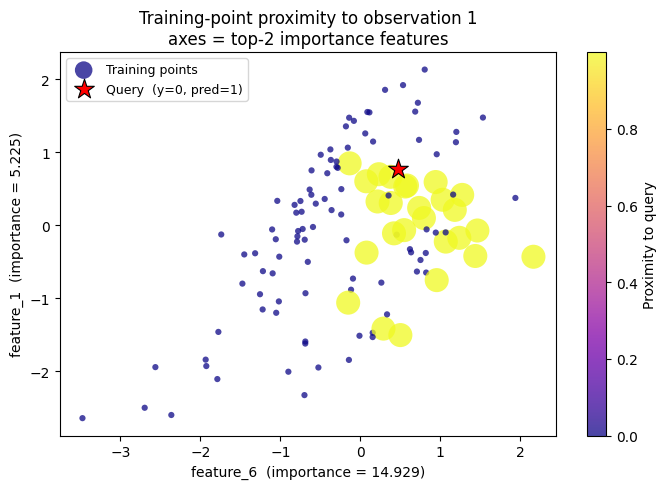

In [9]:
# ── Scatterplot: training points colored & sized by proximity to a query ──────
obs_idx = 1  # change to any value in [0, 4] to select a different query

query_row = X_test.iloc[[obs_idx]]
query_label = y_test[obs_idx]
query_sample_id = X_test.index[obs_idx]

# Proximity of query to every training point  (shape: 1 × n_train)
prox_row = model.prox_extend(query_row)
if hasattr(prox_row, "toarray"):
    prox_row = prox_row.toarray()
prox_weights = prox_row.ravel()

# Choose axes: top-2 features by |importance| for this observation
imp_scores = importance.loc[query_sample_id]
top2 = imp_scores.abs().nlargest(2).index.tolist()
feat_x, feat_y = top2

# Scale marker sizes proportionally to proximity weight
max_prox = prox_weights.max()
s_vals = 20 + 280 * (prox_weights / max_prox if max_prox > 0 else prox_weights)

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    X_train[feat_x], X_train[feat_y],
    c=prox_weights,
    s=s_vals,
    cmap="plasma",
    alpha=0.75,
    edgecolors="none",
    label="Training points",
)
plt.colorbar(sc, ax=ax, label="Proximity to query")

ax.scatter(
    query_row[feat_x], query_row[feat_y],
    c="red", s=220, marker="*", zorder=5,
    edgecolors="black", linewidths=0.8,
    label=f"Query  (y={query_label}, pred={model.predict(query_row)[0]})",
)

ax.set_xlabel(f"{feat_x}  (importance = {imp_scores[feat_x]:.3f})")
ax.set_ylabel(f"{feat_y}  (importance = {imp_scores[feat_y]:.3f})")
ax.set_title(
    f"Training-point proximity to observation {query_sample_id}\n"
    f"axes = top-2 importance features"
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Beeswarm-style summary

A beeswarm-style plot is a reasonable summary for `local_feature_importance`, because it shows the distribution of signed local contribution scores across many observations. Unlike SHAP, these scores are not additive feature attributions, so this plot should be interpreted as a distributional summary in proximity space rather than a decomposition of the model output.

To make the sign comparable across samples, fix a single focal class for every observation in the batch. In the plot below, positive values mean the original feature value supported class `1`, and negative values mean it moved the observation away from class `1`.

In [10]:
# -- Compute a batch of local contributions for one fixed focal class --
focal_class = 1
beeswarm_X = X_test.iloc[:30].copy()
focal_labels = np.full(len(beeswarm_X), focal_class, dtype=int)

beeswarm_importance = model.local_feature_importance(
    beeswarm_X,
    labels=focal_labels,
    perturbation="permute",
    n_repeats=6,
    random_state=0,
)

top_features = (
    beeswarm_importance.abs().mean()
    .sort_values(ascending=False)
    .head(6)
    .index.tolist()
)

beeswarm_importance[top_features].head()

,feature_9,feature_4,feature_6,feature_1,feature_0,feature_8
0,19.407009,-4.656613e-09,-2.910383e-09,-14.790604,1.429164,-2.425319e-10
1,-2.499996,0.000000e+00,-8.827488e+00,-4.354109,0.000000,0.000000e+00
2,0.000000,0.000000e+00,-8.187384e+00,-4.666660,0.000000,0.000000e+00
3,-0.233593,5.208339e-03,-3.749990e-03,-26.274964,1.430207,1.862645e-08
4,-9.333321,0.000000e+00,-1.743456e+01,-13.999981,0.000000,0.000000e+00


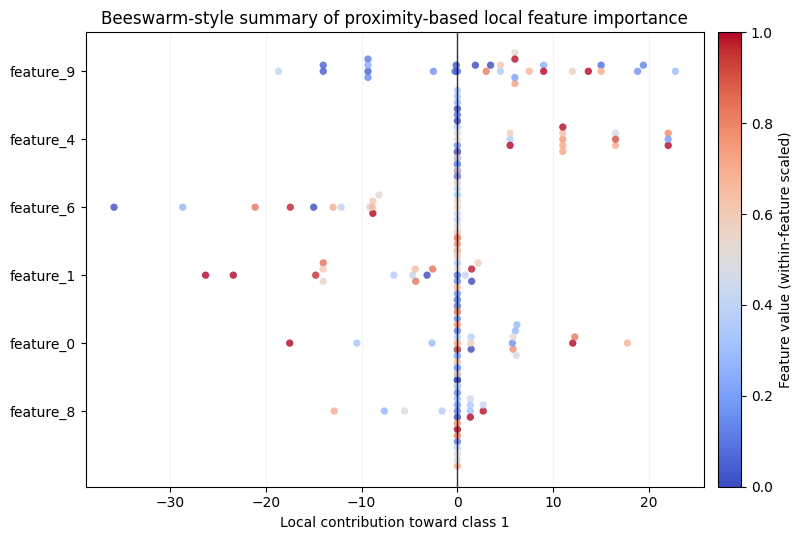

In [11]:
# -- Prototype beeswarm plot for proximity-based local importance --
def beeswarm_offsets(values, step=0.08, bins=18):
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return np.array([])
    if np.allclose(values, values[0]):
        return np.zeros_like(values)

    order = np.argsort(values)
    sorted_values = values[order]
    edges = np.linspace(sorted_values.min(), sorted_values.max(), bins + 1)
    bucket_ids = np.digitize(sorted_values, edges[1:-1], right=False)

    sorted_offsets = np.zeros_like(sorted_values)
    for bucket in np.unique(bucket_ids):
        idx = np.where(bucket_ids == bucket)[0]
        pattern = [0.0]
        for k in range(1, len(idx)):
            level = (k + 1) // 2
            sign = 1.0 if k % 2 else -1.0
            pattern.append(sign * level * step)
        sorted_offsets[idx] = np.array(pattern)

    offsets = np.zeros_like(values)
    offsets[order] = sorted_offsets
    return offsets


fig, ax = plt.subplots(figsize=(8.5, 5.5))
plot_features = list(reversed(top_features))

for y_pos, feature in enumerate(plot_features):
    contributions = beeswarm_importance[feature].to_numpy(dtype=float)
    feature_values = beeswarm_X[feature].to_numpy(dtype=float)
    offsets = beeswarm_offsets(contributions, step=0.09, bins=20)

    lo, hi = np.nanpercentile(feature_values, [5, 95])
    if np.isclose(lo, hi):
        scaled_values = np.full_like(feature_values, 0.5, dtype=float)
    else:
        scaled_values = np.clip((feature_values - lo) / (hi - lo), 0, 1)

    ax.scatter(
        contributions,
        np.full_like(contributions, y_pos, dtype=float) + offsets,
        c=scaled_values,
        cmap="coolwarm",
        s=28,
        alpha=0.8,
        edgecolors="none",
    )

ax.axvline(0.0, color="black", linewidth=1, alpha=0.8)
ax.set_yticks(range(len(plot_features)))
ax.set_yticklabels(plot_features)
ax.set_xlabel(f"Local contribution toward class {focal_class}")
ax.set_title("Beeswarm-style summary of proximity-based local feature importance")
ax.grid(axis="x", alpha=0.15)

sm = plt.cm.ScalarMappable(cmap="coolwarm")
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Feature value (within-feature scaled)")

plt.tight_layout()
plt.show()

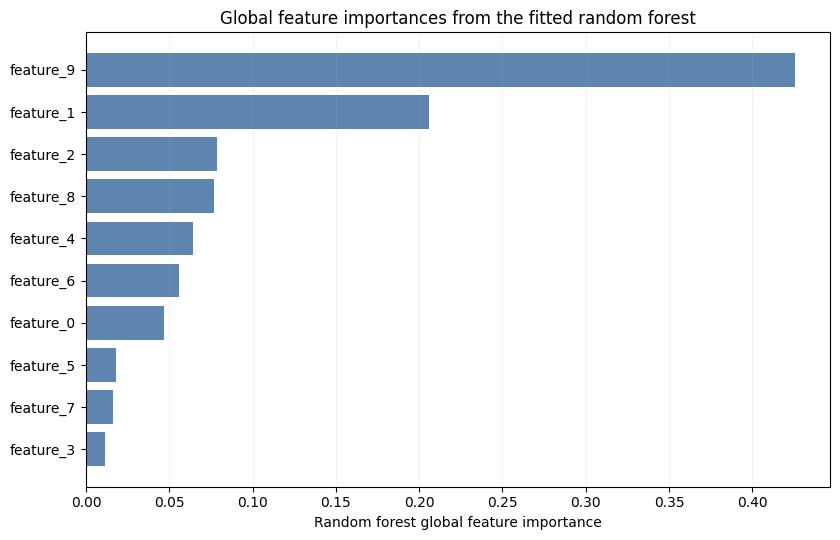

In [12]:
# -- Global random-forest feature importance for comparison --
global_importance = pd.Series(model.feature_importances_, index=X_train.columns)
global_importance = global_importance.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(global_importance.index, global_importance.values, color="#4C78A8", alpha=0.9)
ax.set_xlabel("Random forest global feature importance")
ax.set_title("Global feature importances from the fitted random forest")
ax.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()